# Part 1 - Compare results to table

The goal of this section is to reproduce the original results found in Table 5 of the paper by using evaluation.py to score the authors' released checkpoints for the unsupervised and supervised models.

In [2]:
import json
import random
import subprocess

import matplotlib.pyplot as plt
from prettytable import PrettyTable

cols = ["STS12", "STS13", "STS14", "STS15", "STS16", "STS-B", "SICK-R", "Avg."]

# numbers from the paper (Table 5)
paper = {}
paper["BERT-base (first-last avg.)"] = [39.70, 59.38, 49.67, 66.03, 66.19, 53.87, 62.06, 56.70]
paper["Unsup. SimCSE-BERT-base"] = [68.40, 82.41, 74.38, 80.91, 78.56, 76.85, 72.23, 76.25]
paper["Sup. SimCSE-BERT-base"] = [75.30, 84.67, 80.19, 85.40, 80.82, 84.25, 80.39, 81.57]

reproduced = {}

In [3]:
def evaluate(model_name, pooler):
    # run the original evaluation.py on the 7 STS sets
    command = ["../.venv/bin/python", "evaluation.py",
               "--model_name_or_path", model_name,
               "--pooler", pooler,
               "--task_set", "sts",
               "--mode", "test"]
    result = subprocess.run(command, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stderr[-3000:])
        raise RuntimeError("evaluation.py failed for " + model_name)
    output_lines = result.stdout.splitlines()

    for i in range(len(output_lines)):
        # scores are 2 lines below the header line with "STS12"
        if "STS12" in output_lines[i]:
            score_line = output_lines[i + 2]
            break

    scores = []
    for value in score_line.split("|"):
        value = value.strip()
        if value != "":
            scores.append(float(value))
    return scores


def print_table(rows):
    table = PrettyTable(["Model"] + cols)
    table.float_format = ".2"
    for name in rows:
        table.add_row([name] + rows[name])
    print(table)

In [5]:
reproduced["BERT-base (first-last avg.)"] = evaluate("bert-base-uncased", "avg_first_last")
reproduced["Unsup. SimCSE-BERT-base"] = evaluate("princeton-nlp/unsup-simcse-bert-base-uncased", "cls_before_pooler")
reproduced["Sup. SimCSE-BERT-base"] = evaluate("princeton-nlp/sup-simcse-bert-base-uncased", "cls")

rows = {}
rows["BERT-base first-last avg. (paper)"] = paper["BERT-base (first-last avg.)"]
rows["BERT-base first-last avg. (reproduced)"] = reproduced["BERT-base (first-last avg.)"]
rows["Unsup. SimCSE (paper)"] = paper["Unsup. SimCSE-BERT-base"]
rows["Unsup. SimCSE (reproduced)"] = reproduced["Unsup. SimCSE-BERT-base"]
rows["Sup. SimCSE (paper)"] = paper["Sup. SimCSE-BERT-base"]
rows["Sup. SimCSE (reproduced)"] = reproduced["Sup. SimCSE-BERT-base"]
print_table(rows)

+----------------------------------------+-------+-------+-------+-------+-------+-------+--------+-------+
|                 Model                  | STS12 | STS13 | STS14 | STS15 | STS16 | STS-B | SICK-R |  Avg. |
+----------------------------------------+-------+-------+-------+-------+-------+-------+--------+-------+
|   BERT-base first-last avg. (paper)    | 39.70 | 59.38 | 49.67 | 66.03 | 66.19 | 53.87 | 62.06  | 56.70 |
| BERT-base first-last avg. (reproduced) | 45.09 | 64.30 | 54.56 | 70.52 | 67.87 | 59.05 | 63.75  | 60.73 |
|         Unsup. SimCSE (paper)          | 68.40 | 82.41 | 74.38 | 80.91 | 78.56 | 76.85 | 72.23  | 76.25 |
|       Unsup. SimCSE (reproduced)       | 68.40 | 82.41 | 74.38 | 80.91 | 78.56 | 76.85 | 72.23  | 76.25 |
|          Sup. SimCSE (paper)           | 75.30 | 84.67 | 80.19 | 85.40 | 80.82 | 84.25 | 80.39  | 81.57 |
|        Sup. SimCSE (reproduced)        | 75.30 | 84.67 | 80.19 | 85.40 | 80.82 | 84.26 | 80.39  | 81.58 |
+---------------------------

## Part 2 - Train baseline model

In this section, a new model will be trained on a subset of the Wikipedia sentences used in the paper for time purposes. train.py will be used to train and the model will be evaluated in the same way as in Part 1

In [7]:
# from data/wiki_subset.txt
subset = 128000

with open("data/wiki1m_for_simcse.txt") as f:
    all_sentences = f.readlines()

random.seed(42)
subset = random.sample(all_sentences, subset)

with open("data/wiki_subset.txt", "w") as f:
    f.writelines(subset)

In [8]:
# training
!../.venv/bin/python train.py \
    --model_name_or_path bert-base-uncased \
    --train_file data/wiki_subset.txt \
    --output_dir result/baseline \
    --num_train_epochs 1 \
    --per_device_train_batch_size 64 \
    --learning_rate 3e-5 \
    --max_seq_length 32 \
    --eval_strategy steps \
    --save_strategy best \
    --metric_for_best_model stsb_spearman \
    --load_best_model_at_end \
    --eval_steps 125 \
    --pooler_type cls \
    --mlp_only_train \
    --overwrite_output_dir \
    --temp 0.05 \
    --do_train

<frozen site>:101: RuntimeWarning: Unexpected value in sys.prefix, expected /home/micah/Documents/School/2026/fall/CS536/ML-final-project/.venv, got /home/micah/Documents/School/2026/fall/CS536/ML-final-project/SimCSE/../.venv
<frozen site>:101: RuntimeWarning: Unexpected value in sys.exec_prefix, expected /home/micah/Documents/School/2026/fall/CS536/ML-final-project/.venv, got /home/micah/Documents/School/2026/fall/CS536/ML-final-project/SimCSE/../.venv
11/26/2026 17:57:39 - WARNING - __main__ -   Process rank: -1, device: cuda:0, n_gpu: 1 distributed training: False, 16-bits training: False
11/26/2026 17:57:39 - INFO - __main__ -   Training/evaluation parameters OurTrainingArguments(
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_

In [9]:
# convert it to a checkpoint so evaluation.py can load it
!../.venv/bin/python simcse_to_huggingface.py --path result/baseline

<frozen site>:101: RuntimeWarning: Unexpected value in sys.prefix, expected /home/micah/Documents/School/2026/fall/CS536/ML-final-project/.venv, got /home/micah/Documents/School/2026/fall/CS536/ML-final-project/SimCSE/../.venv
<frozen site>:101: RuntimeWarning: Unexpected value in sys.exec_prefix, expected /home/micah/Documents/School/2026/fall/CS536/ML-final-project/.venv, got /home/micah/Documents/School/2026/fall/CS536/ML-final-project/SimCSE/../.venv
SimCSE checkpoint -> Huggingface checkpoint for result/baseline


In [10]:
reproduced["Unsup. SimCSE-BERT-base (baseline)"] = evaluate("result/baseline", "cls_before_pooler")

## Part 3 - Comparison

Graphically comparing the local baseline model to the paper's model trained on all 1 million sentences

In [11]:
rows = {}
rows["Unsup. SimCSE (paper, 1M sentences)"] = paper["Unsup. SimCSE-BERT-base"]
rows["Unsup. SimCSE (reproduced)"] = reproduced["Unsup. SimCSE-BERT-base"]
rows["Unsup. SimCSE (baseline)"] = reproduced["Unsup. SimCSE-BERT-base (baseline)"]
rows["BERT-base first-last avg. (paper)"] = paper["BERT-base (first-last avg.)"]
rows["BERT-base first-last avg. (reproduced)"] = reproduced["BERT-base (first-last avg.)"]
print_table(rows)

# save results
with open("result/table5_small.json", "w") as f:
    json.dump({"paper": paper, "reproduced": reproduced}, f, indent=2)

+----------------------------------------+-------+-------+-------+-------+-------+-------+--------+-------+
|                 Model                  | STS12 | STS13 | STS14 | STS15 | STS16 | STS-B | SICK-R |  Avg. |
+----------------------------------------+-------+-------+-------+-------+-------+-------+--------+-------+
|  Unsup. SimCSE (paper, 1M sentences)   | 68.40 | 82.41 | 74.38 | 80.91 | 78.56 | 76.85 | 72.23  | 76.25 |
|       Unsup. SimCSE (reproduced)       | 68.40 | 82.41 | 74.38 | 80.91 | 78.56 | 76.85 | 72.23  | 76.25 |
|        Unsup. SimCSE (baseline)        | 63.74 | 76.55 | 68.08 | 77.44 | 76.46 | 72.70 | 68.97  | 71.99 |
|   BERT-base first-last avg. (paper)    | 39.70 | 59.38 | 49.67 | 66.03 | 66.19 | 53.87 | 62.06  | 56.70 |
| BERT-base first-last avg. (reproduced) | 45.09 | 64.30 | 54.56 | 70.52 | 67.87 | 59.05 | 63.75  | 60.73 |
+----------------------------------------+-------+-------+-------+-------+-------+-------+--------+-------+


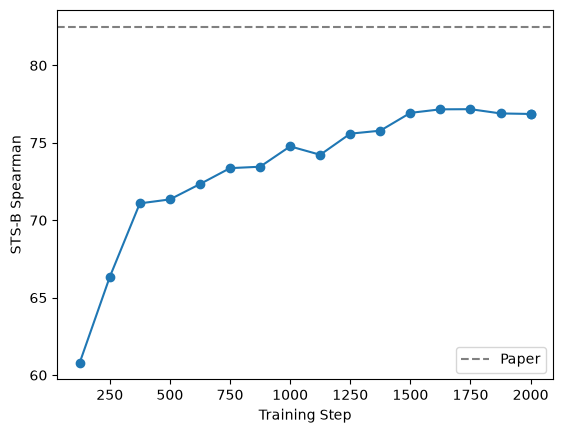

In [12]:
# load the best training state
with open("result/baseline/trainer_state.json") as f:
    trainer_state = json.load(f)

steps = []
dev_scores = []
for entry in trainer_state["log_history"]:
    if "eval_stsb_spearman" in entry:
        steps.append(entry["step"])
        dev_scores.append(entry["eval_stsb_spearman"] * 100)

plt.plot(steps, dev_scores, marker="o")
plt.axhline(82.5, color="gray", linestyle="--", label="Paper")
plt.xlabel("Training Step")
plt.ylabel("STS-B Spearman")
plt.legend()
plt.show()

Hypothesis 1: Training replacing one word per sentence with a synonym will improve the model during transfer learning tasks

In [1]:
import sys 

print(sys.executable)

/home/micah/Documents/School/2026/fall/CS536/ML-final-project/.venv/bin/python


In [5]:
import sys
!{sys.executable} -m pip show PyDictionary

Name: PyDictionary
Version: 2.0.1
Summary: A real dictionary module for Python
Home-page: https://github.com/geekpradd/PyDictionary
Author: geekpradd
Author-email: pradd@outlook.com
License: UNKNOWN
Location: /home/micah/Documents/School/2026/fall/CS536/ML-final-project/.venv/lib/python3.14/site-packages
Requires: bs4, click, goslate, requests
Required-by: 


In [6]:
import importlib.util

print(importlib.util.find_spec("PyDictionary"))

ModuleSpec(name='PyDictionary', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7b69bb235610>, origin='/home/micah/Documents/School/2026/fall/CS536/ML-final-project/.venv/lib/python3.14/site-packages/PyDictionary/__init__.py', submodule_search_locations=['/home/micah/Documents/School/2026/fall/CS536/ML-final-project/.venv/lib/python3.14/site-packages/PyDictionary'])


In [7]:
import PyDictionary
print(PyDictionary.__file__)

/home/micah/Documents/School/2026/fall/CS536/ML-final-project/.venv/lib/python3.14/site-packages/PyDictionary/__init__.py


In [9]:
from PyDictionary import PyDictionary

dictionary = PyDictionary()

In [ ]:
from PyDictionary import PyDictionary
import random


dictionary = PyDictionary()
# from data/wiki_subset.txt
subset = 128000

with open("data/wiki1m_for_simcse.txt") as f:
    all_sentences = f.readlines()

all_synonym_sentances = []  

for l in all_sentences.splitlines():
    print(l)
    input("Press Enter to continue...")  # Wait for user input before proceeding to the next sentence
    words = l.split()
    random.shuffle(words)  # Shuffle the words to get a random word each time
    for word in words:
        synonyms = dictionary.synonym(word)

        if synonyms:
            print("synonym found for word:", word)
            replacement = random.choice(synonyms)

            sentence = sentence.replace(word, replacement, 1)
            break
        else:
            sentence = l  # If no synonyms found, keep the original sentence

    print("synonym sentence:", sentence)
    input("Press Enter to continue...")  # Wait for user input before proceeding to the next sentence
    
    # word = random.choice(words)
    # print(word)
    # synonyms = dictionary.synonym(word)
    # print(l)
    # if synonyms:
    #     all_synonym_sentances.append(l)

random.seed(42)
synonym_subset = random.sample(all_synonym_sentances, subset)

with open("data/wiki_synonym_subset.txt", "w") as f:
    f.writelines(synonym_subset)

YMCA in South Australia

South has no Synonyms in the API
in has no Synonyms in the API
YMCA has no Synonyms in the API
Australia has no Synonyms in the API
synonym sentence: YMCA in South Australia

South Australia (SA)  has a unique position in Australia's history as, unlike the other states which were founded as colonies, South Australia began as a self governing province Many were attracted to this and Adelaide and SA developed as an independent and free thinking state.

self has no Synonyms in the API
position has no Synonyms in the API
Adelaide has no Synonyms in the API
Australia's has no Synonyms in the API
the has no Synonyms in the API
began has no Synonyms in the API
Many has no Synonyms in the API
were has no Synonyms in the API
South has no Synonyms in the API
province has no Synonyms in the API
South has no Synonyms in the API
as has no Synonyms in the API
other has no Synonyms in the API
which has no Synonyms in the API
state. has no Synonyms in the API
and has no Synony